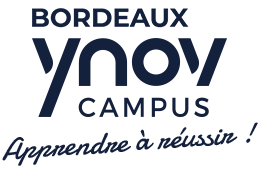

# TP3 — Prévoir la consommation électrique française : baselines → SARIMAX → LSTM → CNN-1D

> **Cours Deep Learning · Ynov Bordeaux · EIA Mastère 2** — TP3 (J3)
> 2h en séance (4h de contenu : parties D à G pour ceux qui finissent en avance) · Résultat attendu en fin de séance : tableau comparatif sur 3 plis du protocole du projet, MAE par jour, figure du 1er mai, conclusion argumentée

**Comment travailler :** exécutez les cellules dans l'ordre. Les cellules marquées `# TODO` sont à compléter. Utilisez `assert` sur les formes dès que vous manipulez des tenseurs. Une cellule à compléter échoue tant que son `TODO` n'est pas fait : c'est normal. Le TP se termine en séance et le corrigé est distribué en fin de TP ; il n'y a rien à rendre.

## Données : le jeu de données du projet

Ce TP travaille directement sur le fichier du projet, **la consommation électrique horaire de la France métropolitaine** (RTE éCO2mix, 2012-2024, 113 976 heures) avec la température de huit villes et le calendrier. Ce que vous construisez aujourd'hui (exploration, baselines, SARIMAX, premier LSTM, premier réseau convolutif 1D, tableau comparatif) est la **première brique de votre projet** : copiez ce notebook dans votre dépôt à la fin de la séance.

**Organisation du TP** : les parties A, B et C sont le tronc commun (2 h en séance) ; les parties D à G, « pour ceux qui finissent en avance », ajoutent 2 h de contenu (analyse d'erreurs, douze plis, ablation, recherche d'hyperparamètres). Rien n'est à rendre.

Le protocole d'évaluation est celui de la fiche projet : horizon 24 h, prévision faite à minuit, douze plis mensuels sur 2024 (sept premiers jours de chaque mois). Pour tenir en deux heures, le TP n'utilise que **trois des douze plis** (janvier, mai, août) ; le passage aux douze plis est une seule ligne à changer.

Le fichier `conso_france_horaire.csv` doit être dans `data/` (sur Colab : `from google.colab import files; files.upload()` puis déplacer le fichier).

In [1]:
import os; os.environ["MKL_THREADING_LAYER"] = "SEQUENTIAL"   # Windows/conda : évite le conflit OpenMP entre numpy (MKL) et PyTorch, doit précéder import numpy
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time, os, warnings; warnings.filterwarnings("ignore")
CANDIDATS = ["data/conso_france_horaire.csv", "conso_france_horaire.csv", "../projet/data/conso_france_horaire.csv", "../../projet/data/conso_france_horaire.csv", "../../../projet/data/conso_france_horaire.csv"]   # dossier du TP, ou corriges/, ou copie locale
path = next((p for p in CANDIDATS if os.path.exists(p)), None)
assert path, "conso_france_horaire.csv introuvable : copiez le fichier du projet dans data/"
df = pd.read_csv(path)
df.index = pd.to_datetime(df["datetime"], utc=True).dt.tz_convert("Europe/Paris"); df = df.drop(columns="datetime")
y = df["consommation_mw"]
print(df.shape, "|", df.index.min().date(), "->", df.index.max().date(), "| valeurs manquantes :", int(df.isna().sum().sum()))
df.head(3)

(113976, 14) | 2012-01-01 -> 2024-12-31 | valeurs manquantes : 0


,consommation_mw,temperature_c,temp_paris,temp_lyon,temp_marseille,temp_lille,temp_bordeaux,temp_nantes,temp_strasbourg,temp_toulouse,jour_ferie,jour_semaine,heure,mois
datetime,,,,,,,,,,,,,,
2012-01-01 00:00:00+01:00,58315.0,11.04,12.0,8.6,11.7,11.2,12.6,12.0,9.1,11.1,1,6,0,1
2012-01-01 01:00:00+01:00,56153.0,11.04,12.1,8.6,11.5,11.1,12.6,12.2,9.1,11.1,1,6,1,1
2012-01-01 02:00:00+01:00,55221.5,10.95,12.1,8.4,11.3,11.0,12.5,12.1,9.1,11.1,1,6,2,1


## Partie A — Exploration, stationnarité, baselines (30 min)

### A1 — Les quatre figures qui valent une heure de modélisation (10 min)
Une semaine d'hiver, une semaine d'été, la consommation en fonction de la température, la moyenne par heure et jour de semaine. Puis la moyenne annuelle, pour repérer les deux ruptures de régime (2020, hiver 2022-2023).

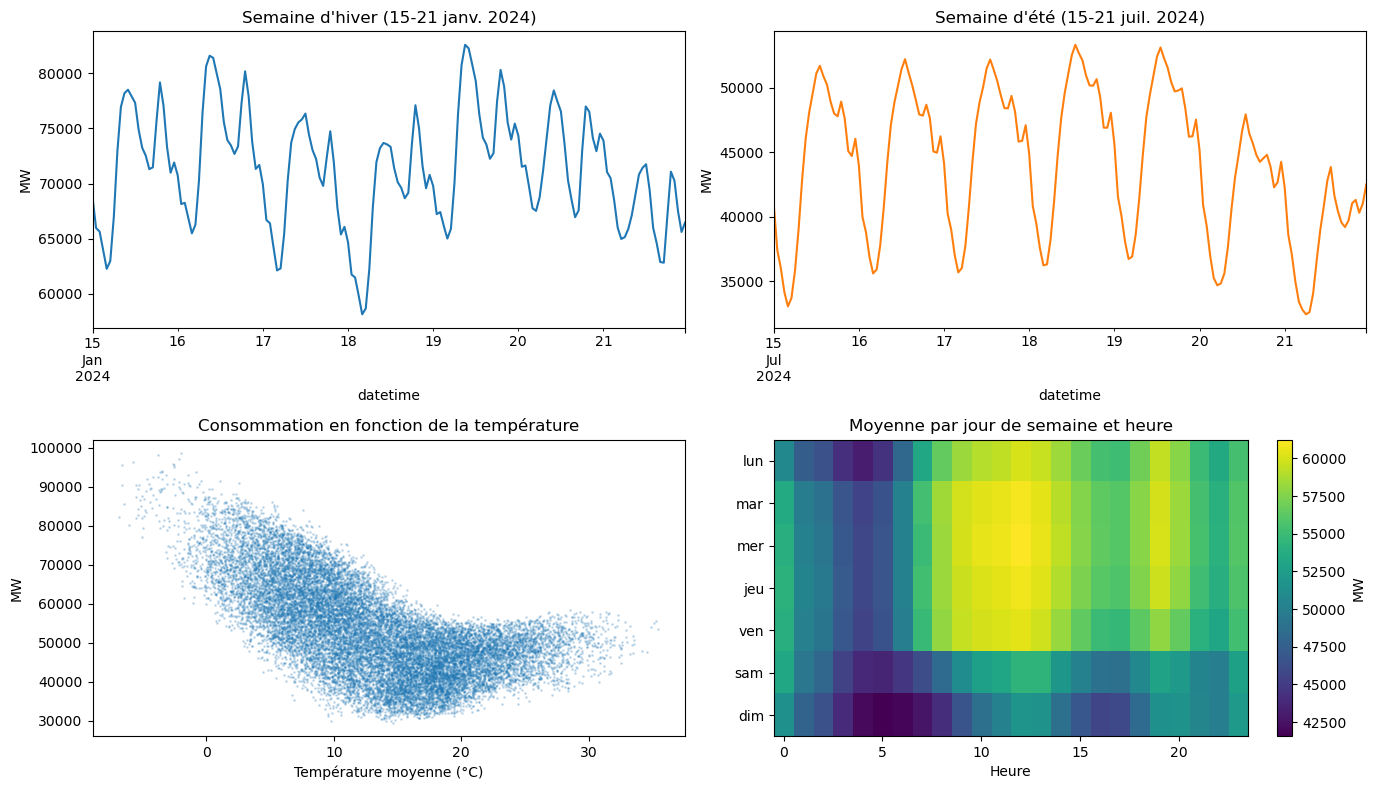

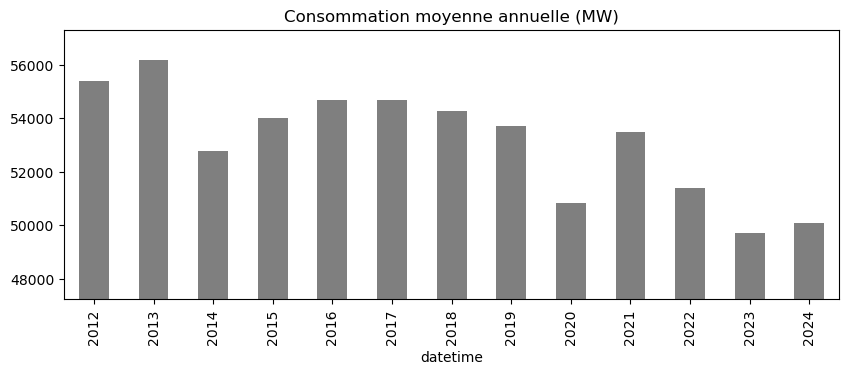

Moyenne : 53,174 MW | min : 29,364 MW | max : 101,650 MW
Record de consommation le : 2012-02-08 19:00:00+01:00


In [2]:
# TODO : quatre sous-figures : une semaine d'hiver (y["2024-01-15":"2024-01-21"]), une semaine d'été, nuage conso vs température, moyenne par (jour_semaine, heure) en image
# --- 1) Les quatre figures ---
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Semaine d'hiver (du lundi 15 au dimanche 21 janvier 2024)
y["2024-01-15":"2024-01-21"].plot(ax=axes[0, 0], color="tab:blue")
axes[0, 0].set_title("Semaine d'hiver (15-21 janv. 2024)"); axes[0, 0].set_ylabel("MW")

# Semaine d'été (du lundi 15 au dimanche 21 juillet 2024)
y["2024-07-15":"2024-07-21"].plot(ax=axes[0, 1], color="tab:orange")
axes[0, 1].set_title("Semaine d'été (15-21 juil. 2024)"); axes[0, 1].set_ylabel("MW")

# Nuage conso vs température (sous-échantillonné : 114 000 points, c'est trop pour un scatter)
ech = df.sample(20000, random_state=0)
axes[1, 0].scatter(ech["temperature_c"], ech["consommation_mw"], s=1, alpha=0.2)
axes[1, 0].set_xlabel("Température moyenne (°C)"); axes[1, 0].set_ylabel("MW")
axes[1, 0].set_title("Consommation en fonction de la température")

# Moyenne par (jour_semaine, heure), en image
prof = df.groupby(["jour_semaine", "heure"])["consommation_mw"].mean().unstack()   # (7, 24)
im = axes[1, 1].imshow(prof, aspect="auto", cmap="viridis")
axes[1, 1].set_yticks(range(7)); axes[1, 1].set_yticklabels(["lun", "mar", "mer", "jeu", "ven", "sam", "dim"])
axes[1, 1].set_xlabel("Heure"); axes[1, 1].set_title("Moyenne par jour de semaine et heure")
fig.colorbar(im, ax=axes[1, 1], label="MW")
plt.tight_layout(); plt.show()

# TODO : moyenne annuelle en barres ; moyenne, min, max de la série et date du record

annuelle = y.groupby(y.index.year).mean()
annuelle.plot.bar(figsize=(10, 3.5), color="tab:gray", title="Consommation moyenne annuelle (MW)")
plt.ylim(annuelle.min() * 0.95, annuelle.max() * 1.02); plt.show()

print(f"Moyenne : {y.mean():,.0f} MW | min : {y.min():,.0f} MW | max : {y.max():,.0f} MW")
print("Record de consommation le :", y.idxmax())

### A2 — Décomposition, stationnarité, ACF et PACF (8 min)
Sur quatre semaines de janvier 2024, pour lire la saisonnalité de 24 h et choisir la différenciation.

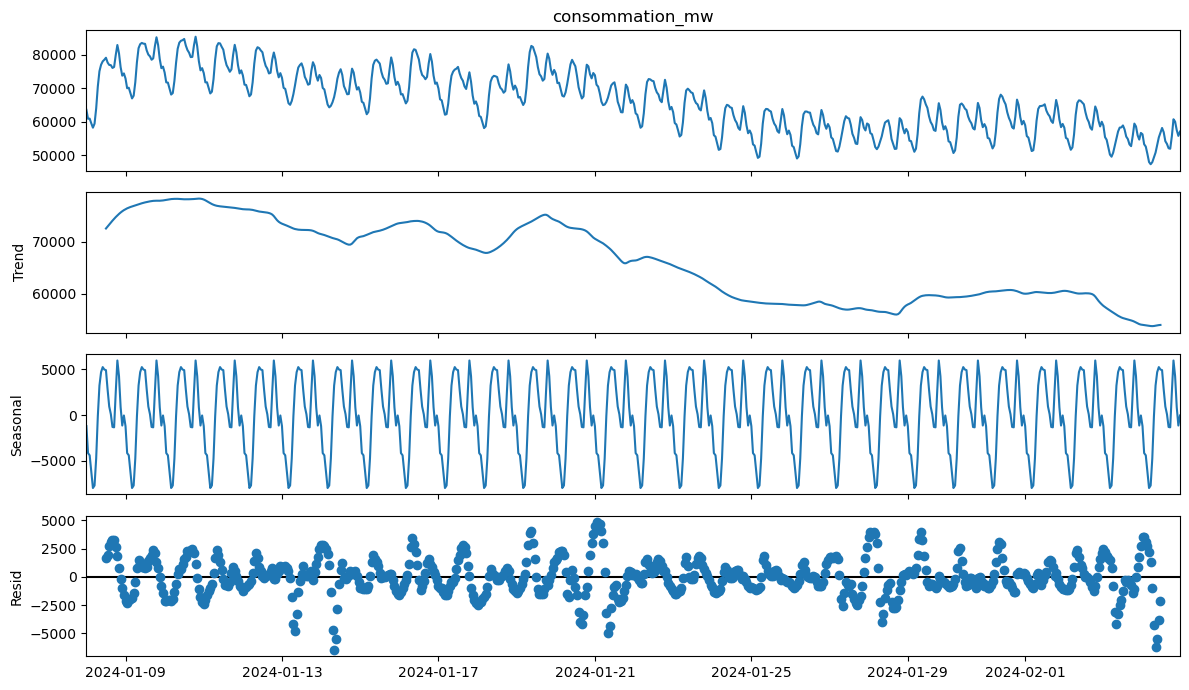

y4 brute                  ADF =    0.10 | p-value = 0.9658 -> non stationnaire (seuil 5 %)
y4 différenciée (24 h)    ADF =   -4.50 | p-value = 0.0002 -> stationnaire (seuil 5 %)


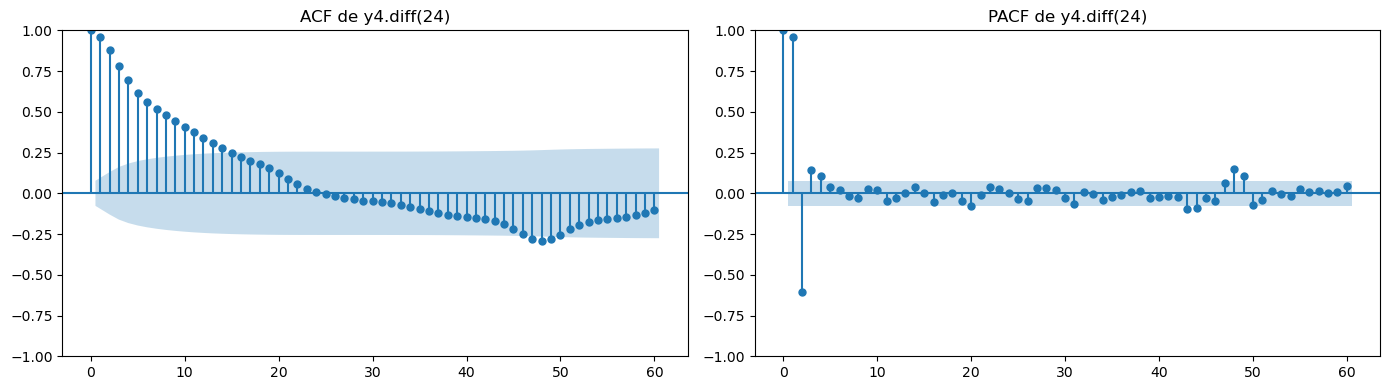

ACF au retard 24 : 0.01 | au retard 168 : 0.25


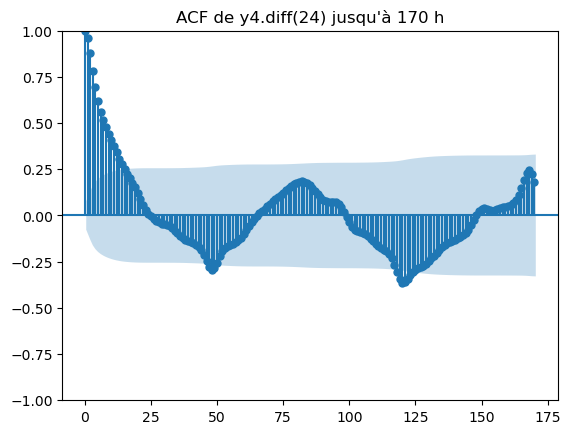

In [3]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
y4 = y["2024-01-08":"2024-02-04"]
# TODO : décomposition (period=24) ; test ADF sur y4 puis sur y4.diff(24) ; ACF et PACF de la série différenciée (lags=60). Que reste-t-il au retard 168 ?

# --- 1) Décomposition (saisonnalité de 24 h) ---
dec = seasonal_decompose(y4, model="additive", period=24)
fig = dec.plot(); fig.set_size_inches(12, 7); plt.tight_layout(); plt.show()

# --- 2) Test ADF : série brute puis différenciée à 24 h ---
def adf(serie, nom):
    stat, pval, *_ = adfuller(serie.dropna())
    print(f"{nom:25s} ADF = {stat:7.2f} | p-value = {pval:.4f} -> {'stationnaire' if pval < 0.05 else 'non stationnaire'} (seuil 5 %)")

y4d = y4.diff(24).dropna()
adf(y4, "y4 brute")
adf(y4d, "y4 différenciée (24 h)")

# --- 3) ACF et PACF de la série différenciée ---
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(y4d, lags=60, ax=axes[0]); axes[0].set_title("ACF de y4.diff(24)")
plot_pacf(y4d, lags=60, ax=axes[1], method="ywm"); axes[1].set_title("PACF de y4.diff(24)")
plt.tight_layout(); plt.show()

# --- 4) Que reste-t-il au retard 168 (une semaine) ? ---
from statsmodels.tsa.stattools import acf
acf_d = acf(y4d, nlags=170)
print(f"ACF au retard 24 : {acf_d[24]:.2f} | au retard 168 : {acf_d[168]:.2f}")
plot_acf(y4d, lags=170); plt.title("ACF de y4.diff(24) jusqu'à 170 h"); plt.show()


### A3 — Le protocole commun et les baselines (12 min)
Pour le pli du mois m, on entraîne sur tout ce qui précède le 1er du mois et on prévoit les sept premiers jours, **jour par jour, à minuit**, avec tout l'historique connu à ce moment-là. Toutes les méthodes, aujourd'hui et dans le projet, sont évaluées exactement ainsi, et une seule MAE (et MAPE) par méthode entre dans le tableau.

In [4]:
H = 24
MOIS_TP = [1, 5, 8]                      # trois plis pour le TP ; pour le projet : list(range(1, 13))
jour = df.index.strftime("%Y-%m-%d").values
yv = y.values.astype(float)

def plis(mois):
    out = []
    for m in mois:
        debut = np.where(jour == f"2024-{m:02d}-01")[0][0]          # position de minuit le 1er du mois
        tr = np.arange(debut)                                       # tout ce qui précède
        jours = [np.where(jour == f"2024-{m:02d}-{d:02d}")[0] for d in range(1, 8)]   # 7 journées
        assert all(len(te) == H for te in jours)
        out.append((tr, jours))
    return out

folds = plis(MOIS_TP)
assert sum(len(te) for _, jours in folds for te in jours) == 504   # 3 plis x 7 jours x 24 h

def metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    e = y_true - y_pred
    return {"MAE (MW)": np.mean(np.abs(e)),
            "RMSE (MW)": np.sqrt(np.mean(e ** 2)),
            "MAPE (%)": 100 * np.mean(np.abs(e) / np.abs(y_true))}

PREDS = {}
def evaluate_method(predict_fn, name):
    vrai, pred = [], []
    for tr, jours in folds:
        preds = predict_fn(tr, jours)                    # 7 vecteurs de 24 valeurs
        assert len(preds) == len(jours)
        for te, p in zip(jours, preds):
            p = np.asarray(p, float).ravel()
            assert p.shape == (len(te),)
            vrai.append(yv[te]); pred.append(p)
    vrai, pred = np.concatenate(vrai), np.concatenate(pred)
    PREDS[name] = pred
    return pd.Series(metrics(vrai, pred), name=name)

# --- Baselines : à minuit du jour te, tout l'historique jusqu'à te[0]-1 est connu ---
def naive_derniere(tr, jours):
    return [np.full(len(te), yv[te[0] - 1]) for te in jours]   # dernière heure connue (23h la veille)

def naive_24(tr, jours):
    return [yv[te - 24] for te in jours]                       # même heure la veille

def naive_168(tr, jours):
    return [yv[te - 168] for te in jours]                      # même heure la semaine précédente

scores = pd.DataFrame([
    evaluate_method(naive_derniere, "dernière valeur connue"),
    evaluate_method(naive_24, "même heure la veille"),
    evaluate_method(naive_168, "même heure la semaine précédente"),
]).round(1)
scores


,MAE (MW),RMSE (MW),MAPE (%)
dernière valeur connue,4420.1,5324.7,9.9
même heure la veille,2877.2,3967.7,6.1
même heure la semaine précédente,3774.3,5092.5,7.8


## Partie B — SARIMA et SARIMAX (35 min)
Une estimation par pli sur les trois dernières semaines (une série de 13 ans ne s'estime pas en séance), puis, chaque jour, on **met à jour l'état** du modèle avec les 21 derniers jours (`res.apply`) sans ré-estimer les paramètres, et on prévoit 24 h. SARIMAX ajoute la température, supposée connue pour les 24 h à venir (prévision météo parfaite, comme dans le protocole).

In [5]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
X = df[["temperature_c"]].values.astype(float)

def sarimax_factory(order=(1, 0, 1), seasonal=(1, 1, 1, 24), exog=True, n_fit=24 * 21):
    def predict(tr, jours):
        # 1) Estimation une seule fois par pli, sur les n_fit dernières heures du train
        fit_idx = tr[-n_fit:]
        mod = SARIMAX(yv[fit_idx], exog=X[fit_idx] if exog else None,
                      order=order, seasonal_order=seasonal,
                      enforce_stationarity=False, enforce_invertibility=False)
        res = mod.fit(disp=False, maxiter=200)
        # 2) Chaque jour : mise à jour de l'état avec les n_fit heures qui précèdent minuit, sans ré-estimer
        preds = []
        for te in jours:
            hist = np.arange(te[0] - n_fit, te[0])
            r = res.apply(yv[hist], exog=X[hist] if exog else None)
            f = r.get_forecast(len(te), exog=X[te] if exog else None).predicted_mean
            preds.append(np.asarray(f))
        return preds
    return predict

t0 = time.time()
s_sarima  = evaluate_method(sarimax_factory(exog=False), "SARIMA")
s_sarimax = evaluate_method(sarimax_factory(exog=True),  "SARIMAX + température")
print(f"SARIMA + SARIMAX : {time.time() - t0:.0f} s")

scores = pd.concat([scores, s_sarima.to_frame().T, s_sarimax.to_frame().T]).round(1)
scores


SARIMA + SARIMAX : 103 s


,MAE (MW),RMSE (MW),MAPE (%)
dernière valeur connue,4420.1,5324.7,9.9
même heure la veille,2877.2,3967.7,6.1
même heure la semaine précédente,3774.3,5092.5,7.8
SARIMA,2292.3,3313.6,4.8
SARIMAX + température,2199.5,3190.6,4.6


### Diagnostic des résidus et prévision avec intervalle
Sur le dernier pli (août 2024), premier jour : le 1er août.

AIC : 6,698
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1           108.8126     57.616      1.889      0.059      -4.112     221.738
ar.L1          0.9827      0.009    109.057      0.000       0.965       1.000
ma.L1          0.6263      0.030     20.685      0.000       0.567       0.686
ar.S.L24       0.1555      0.017      9.067      0.000       0.122       0.189
ma.S.L24      -1.0872      0.053    -20.468      0.000      -1.191      -0.983
sigma2      1.058e+05   9875.890     10.713      0.000    8.64e+04    1.25e+05


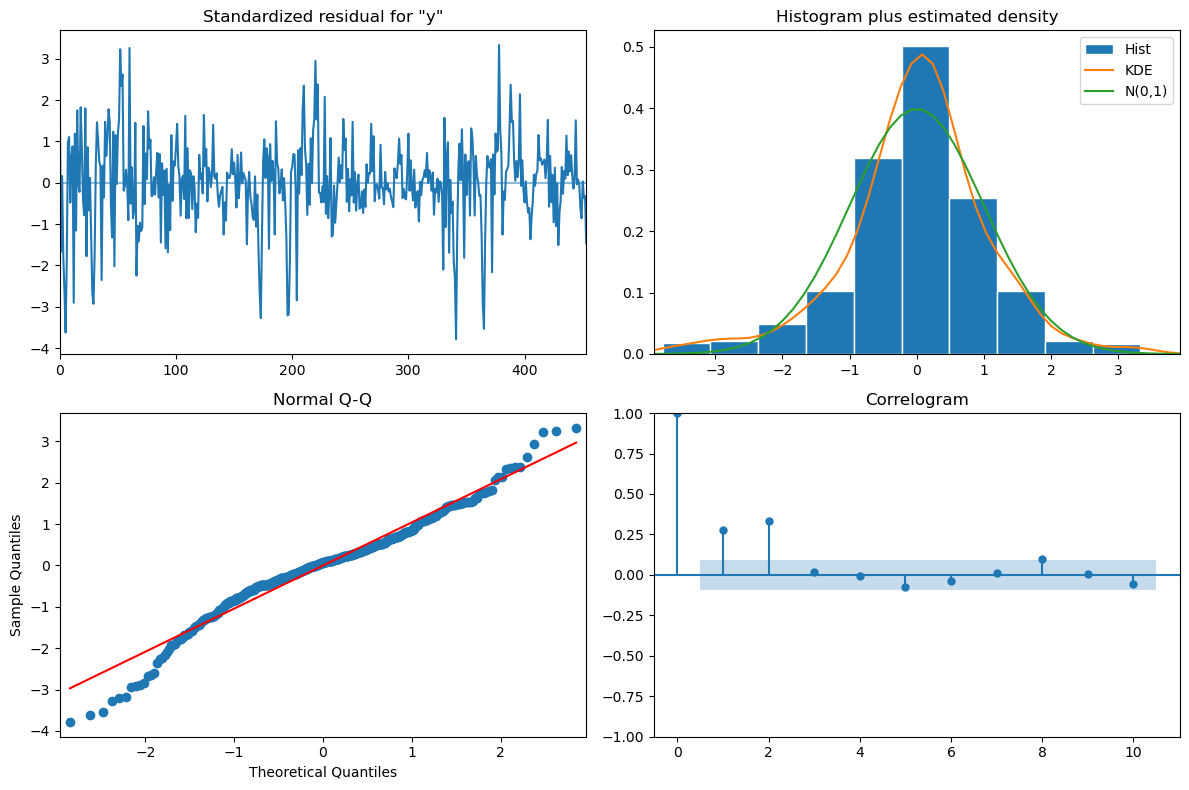

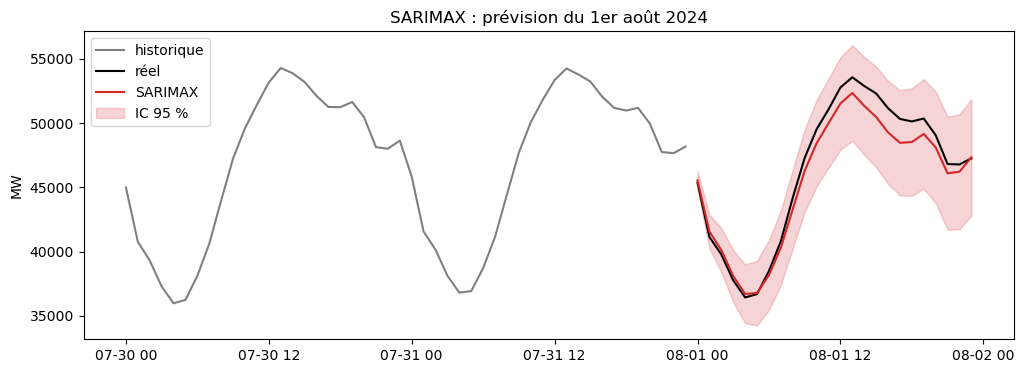

MAE du 1er août : 883 MW | couverture de l'IC 95 % : 100%


In [6]:
# TODO : ajuster SARIMAX sur les 3 dernières semaines avant le 1er août 2024 ; plot_diagnostics ; AIC ; prévision des 24 h du 1er août avec intervalle de confiance (get_forecast(...).conf_int())

debut = np.where(jour == "2024-08-01")[0][0]
fit_idx = np.arange(debut - 24 * 21, debut)          # 3 semaines avant le 1er août
te = np.arange(debut, debut + 24)                    # les 24 h du 1er août

res = SARIMAX(yv[fit_idx], exog=X[fit_idx], order=(1, 0, 1), seasonal_order=(1, 1, 1, 24),
              enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=200)
print(f"AIC : {res.aic:,.0f}")
print(res.summary().tables[1])                       # coefficients (dont celui de la température)

res.plot_diagnostics(figsize=(12, 8)); plt.tight_layout(); plt.show()

fc = res.get_forecast(24, exog=X[te])
moy, ic = np.asarray(fc.predicted_mean), np.asarray(fc.conf_int(alpha=0.05))   # IC à 95 %

ctx = np.arange(debut - 48, debut)                   # 48 h d'historique pour le contexte
plt.figure(figsize=(12, 4))
plt.plot(df.index[ctx], yv[ctx], color="gray", label="historique")
plt.plot(df.index[te], yv[te], color="black", label="réel")
plt.plot(df.index[te], moy, color="tab:red", label="SARIMAX")
plt.fill_between(df.index[te], ic[:, 0], ic[:, 1], color="tab:red", alpha=0.2, label="IC 95 %")
plt.title("SARIMAX : prévision du 1er août 2024"); plt.ylabel("MW"); plt.legend(); plt.show()

print(f"MAE du 1er août : {np.mean(np.abs(yv[te] - moy)):,.0f} MW | "
      f"couverture de l'IC 95 % : {np.mean((yv[te] >= ic[:, 0]) & (yv[te] <= ic[:, 1])):.0%}")


## Partie C — LSTM et réseau convolutif 1D (55 min)
Fenêtre de 168 h en entrée (7 variables : consommation, température, heure et jour de semaine en sinus et cosinus, jour férié), **plus les 24 h de covariables connues à l'avance** (température prévue et calendrier du lendemain), concaténées avant la tête de prédiction. Entraînement sur les **trois dernières années** avant chaque pli ; la normalisation utilise les statistiques du train du pli seulement. GPU recommandé ; sur CPU, comptez une dizaine de minutes pour l'ensemble.

In [7]:
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
torch.manual_seed(0); device = "cuda" if torch.cuda.is_available() else "cpu"
W, ANNEES_TRAIN = 168, 3
# TODO : construire la matrice de variables (T, n) en float32 : consommation, température, et le calendrier encodé comme vous l'entendez (sinus/cosinus de l'heure et du jour, jour férié...)
h_, j_ = df["heure"].values, df["jour_semaine"].values
Z = np.column_stack([
    df["consommation_mw"].values, df["temperature_c"].values,
    np.sin(2 * np.pi * h_ / 24), np.cos(2 * np.pi * h_ / 24),
    np.sin(2 * np.pi * j_ / 7),  np.cos(2 * np.pi * j_ / 7),
    df["jour_ferie"].values,
]).astype(np.float32)
N_IN, N_FUT = Z.shape[1], Z.shape[1] - 1           # 7 variables passées ; 6 covariables connues à l'avance (tout sauf la consommation)
assert Z.shape == (len(df), 7)

# TODO : fenêtrage : pour chaque début s du train, l'entrée passée (W pas), les covariables connues des H heures suivantes (tout sauf la consommation), la cible (H consommations)
#        Attention : n'utiliser que des fenêtres entièrement contenues dans le train du pli, et limiter aux ANNEES_TRAIN dernières années pour le temps de calcul
def make_windows(Zn, tr, max_windows=None):
    fin = tr[-1] + 1                                    # première position hors train (minuit le 1er du mois)
    debut = max(tr[0], fin - 24 * 365 * ANNEES_TRAIN)   # ANNEES_TRAIN dernières années seulement
    starts = np.arange(debut, fin - W - H + 1)          # passé + cible entièrement dans le train
    if max_windows is not None:
        starts = starts[-max_windows:]                  # les fenêtres les plus récentes
    ip = starts[:, None] + np.arange(W)                 # (N, W)
    jf = starts[:, None] + W + np.arange(H)             # (N, H)
    F = Zn[jf]                                          # (N, H, 7)
    Xp = torch.from_numpy(Zn[ip])                                # (N, W, 7)
    Xf = torch.from_numpy(np.ascontiguousarray(F[:, :, 1:]))     # (N, H, 6)
    Y = torch.from_numpy(np.ascontiguousarray(F[:, :, 0]))       # (N, H)
    return Xp, Xf, Y

# TODO : deux modèles de familles différentes, à vous de choisir tailles et profondeur :
#        - un réseau récurrent (nn.LSTM ou nn.GRU, batch_first=True) qui résume la fenêtre passée, puis une tête qui combine ce résumé avec les covariables du lendemain et produit les H valeurs d'un coup
#        - un réseau convolutif 1D (nn.Conv1d attend (batch, canaux, temps) : transposer) avec un pooling global, même tête
class LSTMForecaster(nn.Module):
    def __init__(self, n_in=N_IN, n_fut=N_FUT, hidden=64, dropout=0.1, layers=2):
        super().__init__()
        self.rnn = nn.LSTM(n_in, hidden, num_layers=layers, batch_first=True, dropout=dropout if layers > 1 else 0.0)
        self.head = nn.Sequential(nn.Linear(hidden + H * n_fut, 128), nn.ReLU(), nn.Dropout(dropout), nn.Linear(128, H))
    def forward(self, xp, xf):                          # xp (B, W, n_in), xf (B, H, n_fut)
        _, (h, _) = self.rnn(xp)
        resume = h[-1]                                  # (B, hidden) : état caché de la dernière couche au dernier pas
        return self.head(torch.cat([resume, xf.flatten(1)], dim=1))   # (B, H)

class CNN1DForecaster(nn.Module):
    def __init__(self, n_in=N_IN, n_fut=N_FUT, hidden=64, dropout=0.1):
        super().__init__()
        self.conv = nn.Sequential(                      # convolutions dilatées : champ réceptif de 61 h
            nn.Conv1d(n_in, hidden, kernel_size=5, padding=2), nn.ReLU(),
            nn.Conv1d(hidden, hidden, kernel_size=5, padding=4, dilation=2), nn.ReLU(),
            nn.Conv1d(hidden, hidden, kernel_size=5, padding=8, dilation=4), nn.ReLU(),
            nn.Conv1d(hidden, hidden, kernel_size=5, padding=16, dilation=8), nn.ReLU(),
        )
        self.head = nn.Sequential(nn.Linear(2 * hidden + H * n_fut, 128), nn.ReLU(), nn.Dropout(dropout), nn.Linear(128, H))
    def forward(self, xp, xf):
        z = self.conv(xp.transpose(1, 2))               # (B, hidden, W)
        resume = torch.cat([z.mean(dim=2), z.amax(dim=2)], dim=1)     # pooling global moyen + max : (B, 2*hidden)
        return self.head(torch.cat([resume, xf.flatten(1)], dim=1))   # (B, H)

for cls in (LSTMForecaster, CNN1DForecaster):          # vérification des formes
    assert cls()(torch.zeros(2, W, N_IN), torch.zeros(2, H, N_FUT)).shape == (2, H)

# TODO : une fonction predict(tr, jours) pour evaluate_method : normaliser avec les statistiques du train du pli, entraîner (Adam, L1Loss, clipping du gradient : la boîte à outils du cours), prédire chaque journée à partir des W heures qui la précèdent et de ses covariables, dénormaliser
def dl_factory(model_cls, epochs=8, max_windows=None, lr=1e-3, hidden=64, dropout=0.1, batch_size=256, seed=0, verbose=True):
    def predict(tr, jours):
        torch.manual_seed(seed); np.random.seed(seed)
        fin = tr[-1] + 1
        debut = max(tr[0], fin - 24 * 365 * ANNEES_TRAIN)
        mu, sd = Z[debut:fin, :2].mean(0), Z[debut:fin, :2].std(0)   # statistiques du train du pli seulement
        Zn = Z.copy(); Zn[:, :2] = (Z[:, :2] - mu) / sd               # conso et température ; le calendrier est déjà dans [-1, 1]
        Xp, Xf, Y = make_windows(Zn, tr, max_windows)
        dl = DataLoader(TensorDataset(Xp, Xf, Y), batch_size=batch_size, shuffle=True)
        model = model_cls(hidden=hidden, dropout=dropout).to(device)
        opt, loss_fn = torch.optim.Adam(model.parameters(), lr=lr), nn.L1Loss()
        for ep in range(epochs):
            model.train(); tot = 0.0
            for xp, xf, yb in dl:
                xp, xf, yb = xp.to(device), xf.to(device), yb.to(device)
                opt.zero_grad()
                loss = loss_fn(model(xp, xf), yb)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                opt.step(); tot += loss.item() * len(yb)
            if verbose:
                print(f"  {model_cls.__name__} | pli {jour[fin]} | epoch {ep + 1}/{epochs} | L1 train = {tot / len(Y):.4f} (≈ {tot / len(Y) * sd[0]:,.0f} MW)")
        model.eval(); preds = []
        with torch.no_grad():
            for te in jours:
                xp = torch.from_numpy(Zn[te[0] - W:te[0]])[None].to(device)                  # les W heures avant minuit
                xf = torch.from_numpy(np.ascontiguousarray(Zn[te][:, 1:]))[None].to(device)  # covariables de la journée
                preds.append(model(xp, xf).cpu().numpy()[0] * sd[0] + mu[0])               # dénormalisation
        predict.model = model
        return preds
    return predict

# TODO : ajouter les deux réseaux à `scores` et afficher leur nombre de paramètres
def n_params(m): return sum(p.numel() for p in m.parameters())
print(f"Paramètres : LSTM = {n_params(LSTMForecaster()):,} | CNN-1D = {n_params(CNN1DForecaster()):,} | device = {device}")
t0 = time.time(); s_lstm = evaluate_method(dl_factory(LSTMForecaster), "LSTM");   print(f"LSTM : {time.time() - t0:.0f} s")
t0 = time.time(); s_cnn = evaluate_method(dl_factory(CNN1DForecaster), "CNN-1D"); print(f"CNN-1D : {time.time() - t0:.0f} s")
scores = pd.concat([scores, s_lstm.to_frame().T, s_cnn.to_frame().T]).round(1)
scores

Paramètres : LSTM = 81,816 | CNN-1D = 101,976 | device = cuda
  LSTMForecaster | pli 2024-01-01 | epoch 1/8 | L1 train = 0.3281 (≈ 3,701 MW)
  LSTMForecaster | pli 2024-01-01 | epoch 2/8 | L1 train = 0.1795 (≈ 2,025 MW)
  LSTMForecaster | pli 2024-01-01 | epoch 3/8 | L1 train = 0.1603 (≈ 1,808 MW)
  LSTMForecaster | pli 2024-01-01 | epoch 4/8 | L1 train = 0.1502 (≈ 1,695 MW)
  LSTMForecaster | pli 2024-01-01 | epoch 5/8 | L1 train = 0.1426 (≈ 1,609 MW)
  LSTMForecaster | pli 2024-01-01 | epoch 6/8 | L1 train = 0.1360 (≈ 1,534 MW)
  LSTMForecaster | pli 2024-01-01 | epoch 7/8 | L1 train = 0.1316 (≈ 1,485 MW)
  LSTMForecaster | pli 2024-01-01 | epoch 8/8 | L1 train = 0.1284 (≈ 1,449 MW)
  LSTMForecaster | pli 2024-05-01 | epoch 1/8 | L1 train = 0.3265 (≈ 3,528 MW)
  LSTMForecaster | pli 2024-05-01 | epoch 2/8 | L1 train = 0.1788 (≈ 1,932 MW)
  LSTMForecaster | pli 2024-05-01 | epoch 3/8 | L1 train = 0.1594 (≈ 1,723 MW)
  LSTMForecaster | pli 2024-05-01 | epoch 4/8 | L1 train = 0.1503 (≈ 

,MAE (MW),RMSE (MW),MAPE (%)
dernière valeur connue,4420.1,5324.7,9.9
même heure la veille,2877.2,3967.7,6.1
même heure la semaine précédente,3774.3,5092.5,7.8
SARIMA,2292.3,3313.6,4.8
SARIMAX + température,2199.5,3190.6,4.6
LSTM,1364.5,1811.4,2.8
CNN-1D,1232.3,1632.4,2.6


### Tableau final, figure et erreur jour par jour
Le tableau est **le** résultat : baselines en première ligne, toutes les méthodes sur les mêmes 504 heures. Puis l'erreur par jour : où les réseaux gagnent-ils ? Regardez le 1er mai (férié) et le 8 mai.

,MAE (MW),RMSE (MW),MAPE (%)
CNN-1D,1232.3,1632.4,2.6
LSTM,1364.5,1811.4,2.8
SARIMAX + température,2199.5,3190.6,4.6
SARIMA,2292.3,3313.6,4.8
même heure la veille,2877.2,3967.7,6.1
même heure la semaine précédente,3774.3,5092.5,7.8
dernière valeur connue,4420.1,5324.7,9.9


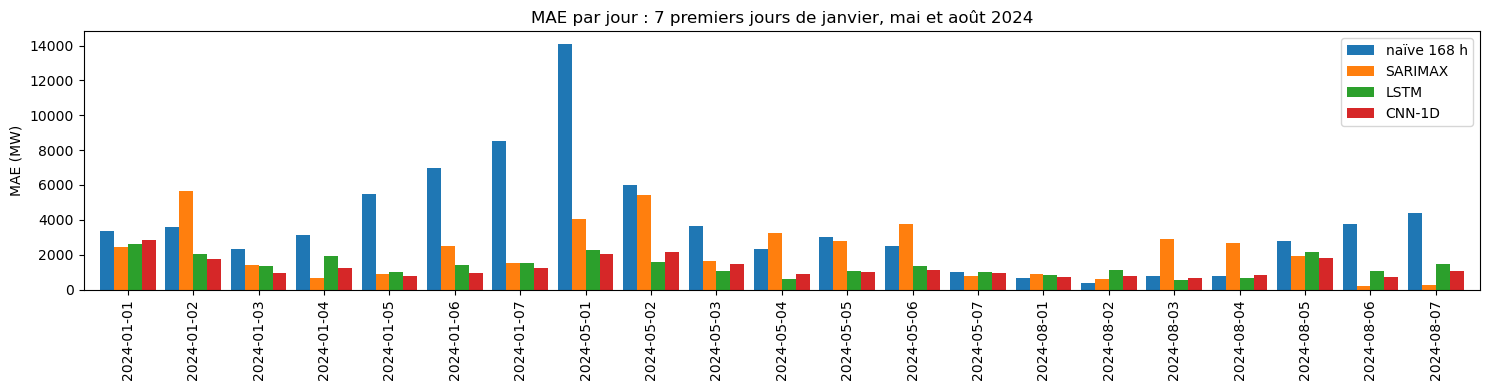

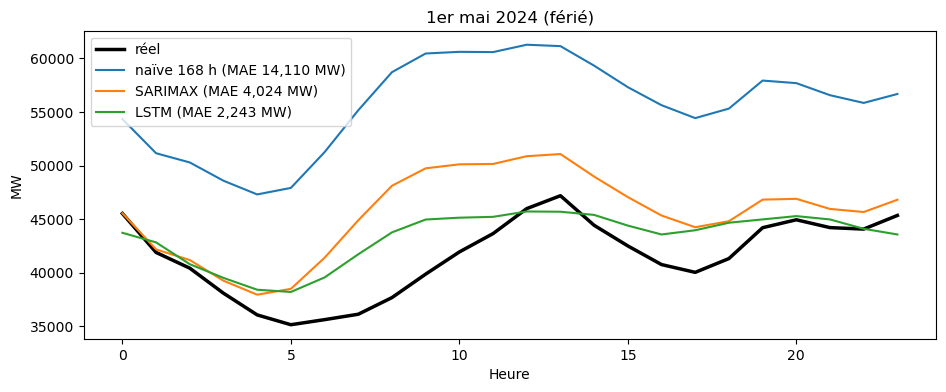

In [8]:
# TODO : tableau trié par MAE ; MAE par jour (21 jours) pour la naïve 168 h, SARIMAX, LSTM, CNN-1D en barres ; figure du 1er mai 2024 (réel, naïve 168 h, SARIMAX, LSTM)
display(scores.sort_values("MAE (MW)"))

reel = np.concatenate([yv[te] for _, jours in folds for te in jours]).reshape(21, 24)
dates = [jour[te[0]] for _, jours in folds for te in jours]
METH = {"naïve 168 h": "même heure la semaine précédente", "SARIMAX": "SARIMAX + température", "LSTM": "LSTM", "CNN-1D": "CNN-1D"}

# MAE par jour (21 jours)
mae_jour = pd.DataFrame({lab: np.abs(PREDS[k].reshape(21, 24) - reel).mean(axis=1) for lab, k in METH.items()}, index=dates)
ax = mae_jour.plot.bar(figsize=(15, 4), width=0.85)
ax.set_ylabel("MAE (MW)"); ax.set_title("MAE par jour : 7 premiers jours de janvier, mai et août 2024")
plt.tight_layout(); plt.show()

# Figure du 1er mai 2024 (férié)
i = dates.index("2024-05-01")
plt.figure(figsize=(11, 4))
plt.plot(range(24), reel[i], "k-", lw=2.5, label="réel")
for lab in ["naïve 168 h", "SARIMAX", "LSTM"]:
    plt.plot(range(24), PREDS[METH[lab]].reshape(21, 24)[i], label=f"{lab} (MAE {mae_jour.loc['2024-05-01', lab]:,.0f} MW)")
plt.xlabel("Heure"); plt.ylabel("MW"); plt.title("1er mai 2024 (férié)"); plt.legend(); plt.show()

## Conclusion à rédiger (3 phrases)
Les réseaux apportent-ils quelque chose sur ces trois plis ? Où exactement (jours ordinaires, jours fériés, changements de température) ? Que recommanderiez-vous aux acheteurs d'énergie à ce stade (coût, explicabilité, intervalles) ?

## Pour le projet
1. Copiez ce notebook dans votre dépôt et passez `MOIS_TP` aux douze mois : c'est le tableau attendu à la soutenance, les baselines en première ligne.
2. Les baselines et le SARIMAX que vous venez de chiffrer sont ce que vous déploierez sur Hugging Face à la journée 4 ; le LSTM et le CNN-1D sont vos deux premiers réseaux, à suivre dans MLflow à partir de la journée 5.
3. Pistes : plus d'historique ou moins, un perceptron sur fenêtre comme troisième famille, la température des huit villes plutôt que la moyenne, les vacances scolaires, les lendemains de jour férié, la pondération des années récentes (2022-2023 a changé le niveau de la série).

---

# Pour ceux qui finissent en avance (2 h de contenu supplémentaire)

Quatre parties indépendantes, dans l'ordre que vous voulez. Elles réutilisent tout ce qui précède (`folds`, `PREDS`, `scores`, `LSTMForecaster`, `make_windows`). Rien n'est à rendre ; le corrigé est distribué en fin de TP et vous pouvez les terminer chez vous. Les parties D et E ne demandent aucun entraînement ; F et G entraînent de petits réseaux avec un budget réduit (quelques minutes sur CPU).

## Partie D — Analyse d'erreurs : où et quand se trompe-t-on ? (25 min)

Une MAE moyenne cache tout. Avant d'améliorer un modèle, on regarde **où** il se trompe : à quelle heure, sur quel pli, sur quel type de jour. C'est la première question que le jury vous posera en soutenance.

À partir de `PREDS` (les prévisions de chaque méthode, 21 jours de 24 heures) : l'erreur moyenne par heure de la journée, par pli, les jours fériés contre les jours ordinaires, et les cinq pires jours du LSTM.

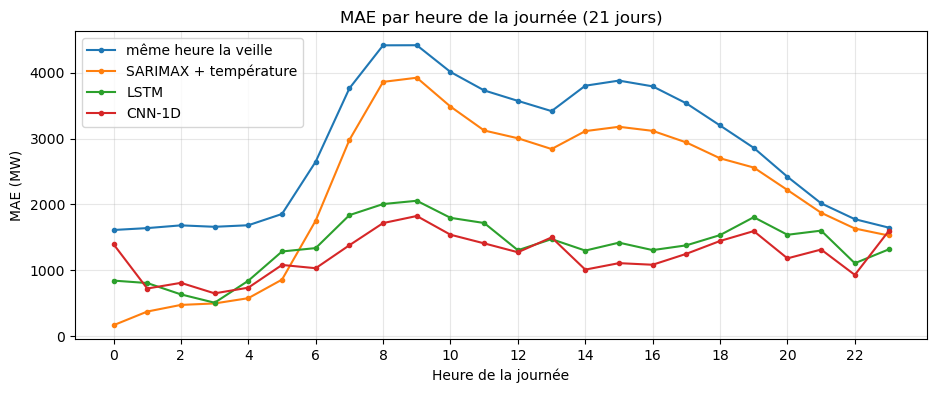

,même heure la veille,SARIMAX + température,LSTM,CNN-1D
janvier,2307.0,2155.0,1697.0,1382.0
mai,4248.0,3086.0,1273.0,1367.0
août,2076.0,1357.0,1123.0,948.0


Jours fériés parmi les 21 jours : ['2024-01-01', '2024-05-01']


,même heure la veille,SARIMAX + température,LSTM,CNN-1D
jours fériés,4289.00,3220.00,2419.00,2437.0
jours ordinaires,2729.00,2092.00,1254.00,1106.0
rapport férié / ordinaire,1.57,1.54,1.93,2.2


,date,jour,férié,MAE LSTM (MW),MAE « la veille » (MW)
0,2024-01-01,lun,True,2595.0,2536.0
1,2024-05-01,mer,True,2243.0,6041.0
2,2024-08-05,lun,False,2142.0,4048.0
3,2024-01-02,mar,False,2060.0,5996.0
4,2024-01-04,jeu,False,1952.0,948.0


In [10]:
noms = ["même heure la veille", "SARIMAX + température", "LSTM", "CNN-1D"]
reel = None   # TODO : tableau (21, 24) des consommations réelles des 21 jours prévus
reel = np.concatenate([yv[te] for _, jours in folds for te in jours]).reshape(21, 24)
err = None    # TODO : dictionnaire nom -> erreur absolue (21, 24) à partir de PREDS
err = {n: np.abs(PREDS[n].reshape(21, 24) - reel) for n in noms}
assert reel.shape == (21, 24)

premiers = [te[0] for _, jours in folds for te in jours]               # position de minuit de chacun des 21 jours
dates = [jour[p] for p in premiers]
ferie = df["jour_ferie"].values[premiers].astype(bool)                 # (21,)
JOURS_FR = ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
jsem = [JOURS_FR[j] for j in df["jour_semaine"].values[premiers]]

# TODO 1 : MAE par heure de la journée (une courbe par méthode)
plt.figure(figsize=(11, 4))
for n in noms:
    plt.plot(range(24), err[n].mean(axis=0), marker="o", ms=3, label=n)
plt.xlabel("Heure de la journée"); plt.ylabel("MAE (MW)"); plt.xticks(range(0, 24, 2))
plt.title("MAE par heure de la journée (21 jours)"); plt.legend(); plt.grid(alpha=0.3); plt.show()

# TODO 2 : MAE par pli (janvier, mai, août), en tableau
mae_pli = pd.DataFrame({n: [err[n][7 * k:7 * (k + 1)].mean() for k in range(3)] for n in noms},
                       index=["janvier", "mai", "août"]).round(0)
display(mae_pli)

# TODO 3 : MAE des jours fériés contre les jours ordinaires (colonne jour_ferie)
print("Jours fériés parmi les 21 jours :", [d for d, f in zip(dates, ferie) if f])
mae_ferie = pd.DataFrame({n: {"jours fériés": err[n][ferie].mean(), "jours ordinaires": err[n][~ferie].mean()} for n in noms}).round(0)
mae_ferie.loc["rapport férié / ordinaire"] = (mae_ferie.loc["jours fériés"] / mae_ferie.loc["jours ordinaires"]).round(2)
display(mae_ferie)

# TODO 4 : les cinq pires jours du LSTM, avec l'erreur de la veille ce jour-là
mae_jour_lstm, mae_jour_veille = err["LSTM"].mean(axis=1), err["même heure la veille"].mean(axis=1)
pires = np.argsort(mae_jour_lstm)[::-1][:5]
display(pd.DataFrame({
    "date": [dates[i] for i in pires],
    "jour": [jsem[i] for i in pires],
    "férié": [bool(ferie[i]) for i in pires],
    "MAE LSTM (MW)": mae_jour_lstm[pires].round(0),
    "MAE « la veille » (MW)": mae_jour_veille[pires].round(0),
}))

**À rédiger (3 lignes)** : à quelles heures le LSTM se trompe-t-il le plus ? Sur quel pli ? Les jours fériés lui coûtent-ils encore cher, et combien coûtent-ils à « la veille » ?

## Partie E — Les douze plis du protocole du projet, pour les baselines (15 min)

Le TP n'utilise que trois plis (janvier, mai, août). Le projet en demande **douze**, soit 2 016 heures. Pour les baselines, cela ne coûte rien : recalculez-les sur les douze plis et comparez. Les trois plis du TP étaient-ils représentatifs ? Quel mois est le plus difficile ?

,MAE 3 plis (MW),MAE 12 plis (MW),MAPE 12 plis (%),écart 12 - 3 (%)
dernière valeur connue,4420.1,4310.2,9.4,-2.5
même heure la veille,2877.2,2485.8,5.1,-13.6
même heure la semaine précédente,3774.3,2644.1,5.3,-29.9


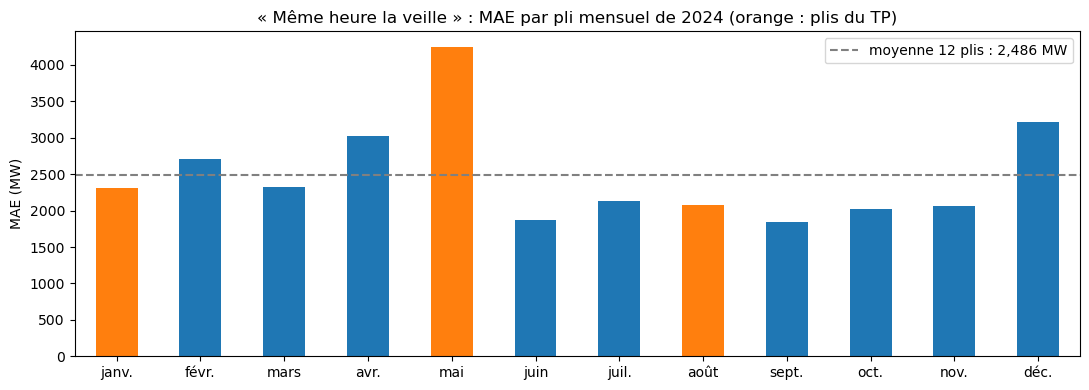

Mois le plus difficile : mai (4,248 MW) | le plus facile : sept. (1,848 MW)


In [11]:
folds12 = None      # TODO : les douze plis de 2024 avec la fonction plis
folds12 = plis(list(range(1, 13)))
def scores_sur(plis_, predict_fn):
    # TODO : comme evaluate_method, mais sur la liste de plis passée en argument ; renvoie metrics(...)
    vrai, pred = [], []
    for tr, jours in plis_:
        preds = predict_fn(tr, jours)
        for te, p in zip(jours, preds):
            vrai.append(yv[te]); pred.append(np.asarray(p, float).ravel())
    return metrics(np.concatenate(vrai), np.concatenate(pred))
# TODO : tableau MAE sur 3 plis contre 12 plis pour les trois baselines
BASELINES = {"dernière valeur connue": naive_derniere,
             "même heure la veille": naive_24,
             "même heure la semaine précédente": naive_168}
comp = pd.DataFrame({
    "MAE 3 plis (MW)":  {n: scores_sur(folds, f)["MAE (MW)"] for n, f in BASELINES.items()},
    "MAE 12 plis (MW)": {n: scores_sur(folds12, f)["MAE (MW)"] for n, f in BASELINES.items()},
    "MAPE 12 plis (%)": {n: scores_sur(folds12, f)["MAPE (%)"] for n, f in BASELINES.items()},
})
comp["écart 12 - 3 (%)"] = 100 * (comp["MAE 12 plis (MW)"] / comp["MAE 3 plis (MW)"] - 1)
display(comp.round(1))
assert sum(len(te) for _, jours in folds12 for te in jours) == 2016
# TODO : MAE de « même heure la veille » mois par mois, en barres ; mois le plus difficile ?
MOIS_FR = ["janv.", "févr.", "mars", "avr.", "mai", "juin", "juil.", "août", "sept.", "oct.", "nov.", "déc."]
mae_mois = pd.Series([scores_sur([f], naive_24)["MAE (MW)"] for f in folds12], index=MOIS_FR)
couleurs = ["tab:orange" if m in ("janv.", "mai", "août") else "tab:blue" for m in MOIS_FR]   # en orange : les 3 plis du TP
ax = mae_mois.plot.bar(figsize=(11, 4), color=couleurs, rot=0)
ax.axhline(mae_mois.mean(), color="gray", ls="--", label=f"moyenne 12 plis : {mae_mois.mean():,.0f} MW")
ax.set_ylabel("MAE (MW)"); ax.set_title("« Même heure la veille » : MAE par pli mensuel de 2024 (orange : plis du TP)"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Mois le plus difficile : {mae_mois.idxmax()} ({mae_mois.max():,.0f} MW) | le plus facile : {mae_mois.idxmin()} ({mae_mois.min():,.0f} MW)")

## Partie F — Ablation : que valent les covariables du lendemain ? (30 min)

Le LSTM reçoit deux choses : la semaine passée (168 h × 7 variables) et les **covariables connues du lendemain** (température prévue, heure, jour de semaine, jour férié). Laquelle fait gagner ? Une ablation répond : on retire un ingrédient et on mesure.

Entraînez deux LSTM identiques sur le pli de **mai** (celui du 1er mai), avec le même budget réduit (un an d'entraînement) : l'un complet, l'autre qui ne voit pas les covariables du lendemain (on les remplace par des zéros). Comparez jour par jour.

Deux entraînements : 4 s


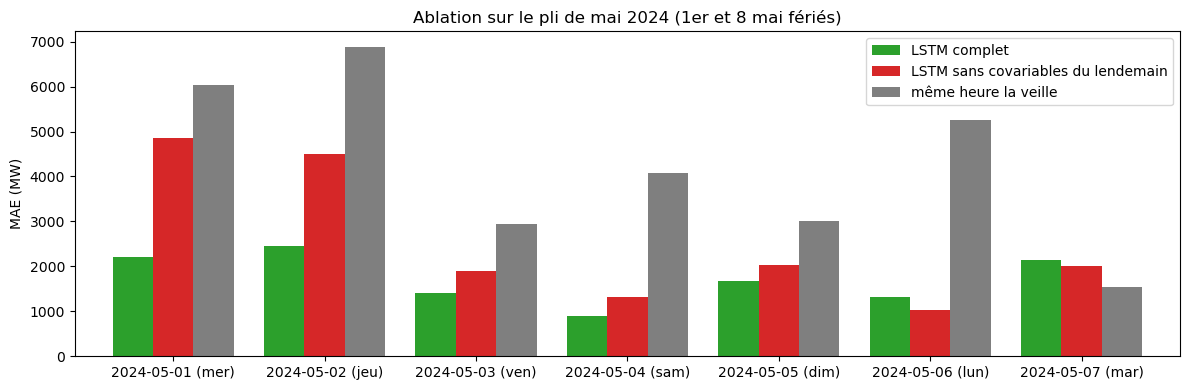

,LSTM complet,LSTM sans covariables du lendemain,même heure la veille
2024-05-01 (mer),2212.0,4851.0,6041.0
2024-05-02 (jeu),2447.0,4506.0,6885.0
2024-05-03 (ven),1417.0,1904.0,2938.0
2024-05-04 (sam),899.0,1322.0,4085.0
2024-05-05 (dim),1678.0,2038.0,2999.0
2024-05-06 (lun),1315.0,1020.0,5256.0
2024-05-07 (mar),2142.0,2018.0,1533.0
moyenne 7 jours,1730.0,2523.0,4248.0


1er mai : avec = 2,212 MW | sans = 4,851 MW | la veille = 6,041 MW
Moyenne : avec = 1,730 MW | sans = 2,523 MW | gain des covariables du lendemain = 31 %


In [12]:
def mae_par_jour(predict_fn, k):
    # TODO : MAE de chacune des 7 journées du pli k (0 = janvier, 1 = mai, 2 = août)
    tr, jours = folds[k]
    preds = predict_fn(tr, jours)
    return np.array([np.mean(np.abs(yv[te] - np.asarray(p).ravel())) for te, p in zip(jours, preds)])

class LSTMSansFutur(LSTMForecaster):
    def forward(self, xp, xf):
        # TODO : appeler le forward du parent en remplaçant xf par des zéros de même forme
        return super().forward(xp, torch.zeros_like(xf))

UN_AN = 24 * 365
# TODO : entraîner les deux réseaux sur le pli de mai (dl_factory(..., epochs=6, max_windows=UN_AN)), même graine
avec, sans = None, None
t0 = time.time()
avec = mae_par_jour(dl_factory(LSTMForecaster, epochs=6, max_windows=UN_AN, seed=0, verbose=False), 1)
sans = mae_par_jour(dl_factory(LSTMSansFutur,  epochs=6, max_windows=UN_AN, seed=0, verbose=False), 1)
print(f"Deux entraînements : {time.time() - t0:.0f} s")
assert len(avec) == 7 and len(sans) == 7
# TODO : barres jour par jour ; MAE moyenne ; que se passe-t-il le 1er mai ?
dates_mai = [jour[te[0]] for te in folds[1][1]]
veille_mai = mae_par_jour(naive_24, 1)                      # repère : la baseline « même heure la veille »
abl = pd.DataFrame({"LSTM complet": avec, "LSTM sans covariables du lendemain": sans, "même heure la veille": veille_mai},
                   index=[f"{d} ({['lun','mar','mer','jeu','ven','sam','dim'][pd.Timestamp(d).dayofweek]})" for d in dates_mai])
ax = abl.plot.bar(figsize=(12, 4), width=0.8, rot=0, color=["tab:green", "tab:red", "tab:gray"])
ax.set_ylabel("MAE (MW)"); ax.set_title("Ablation sur le pli de mai 2024 (1er et 8 mai fériés)")
plt.tight_layout(); plt.show()

abl.loc["moyenne 7 jours"] = abl.mean()
display(abl.round(0))
print(f"1er mai : avec = {avec[0]:,.0f} MW | sans = {sans[0]:,.0f} MW | la veille = {veille_mai[0]:,.0f} MW")
print(f"Moyenne : avec = {avec.mean():,.0f} MW | sans = {sans.mean():,.0f} MW | gain des covariables du lendemain = {100 * (1 - avec.mean() / sans.mean()):.0f} %")

**À rédiger (2 lignes)** : d'où vient l'avantage des réseaux sur SARIMA dans le tableau final : de l'architecture récurrente, ou des informations qu'on leur donne ?

## Partie G — Recherche d'hyperparamètres : au hasard, puis bayésienne (50 min)

Le LSTM du TP a été réglé à la main : learning rate 0,001, état caché 64, dropout 0,1. Sont-ce de bons choix ? On applique la méthode du rappel de ce matin :

1. **un jeu de validation qui respecte le temps** : sur le pli d'août, on met de côté les sept derniers jours de juillet. On s'entraîne sur ce qui précède, on compare les réglages sur ces sept jours, et on ne touche au test (les sept premiers jours d'août) qu'une seule fois, à la fin ;
2. **une recherche au hasard** : six réglages tirés au sort (learning rate en échelle log, taille de l'état caché, dropout) ;
3. **une recherche bayésienne** avec Optuna (`pip install optuna`), huit essais ;
4. **le verdict sur le test**, avec le même budget pour le réglage par défaut et pour le meilleur réglage trouvé.

Le budget est volontairement réduit (six mois de fenêtres, trois epochs par essai) pour tenir sur CPU : les MAE sont donc plus hautes que dans le tableau final. Sur GPU, augmentez `max_windows` et `epochs`.

In [13]:
tr_aout, jours_test = folds[2]
tr_fit = None        # TODO : le train d'août sans ses 7 derniers jours
jours_val = None     # TODO : ces 7 derniers jours, en 7 journées de 24 h (np.split)
tr_fit = tr_aout[:-7 * H]                          # tout jusqu'au 24 juillet 23 h
jours_val = np.split(tr_aout[-7 * H:], 7)          # 25 -> 31 juillet, 7 x 24 h
assert len(jours_val) == 7 and all(len(te) == H for te in jours_val) and jour[jours_val[0][0]] == "2024-07-25"

def entrainer_et_valider(hp, tr, jours, epochs=3, max_windows=24 * 180, seed=0):
    # TODO : reprendre la boucle de dl_factory avec hp["lr"], hp["hidden"], hp["dropout"] ; renvoyer la MAE (MW) sur `jours`
    # dl_factory contient déjà toute la boucle (normalisation sur `tr`, fenêtres dans `tr`, Adam + L1 + clipping) : on la réutilise
    predict = dl_factory(LSTMForecaster, epochs=epochs, max_windows=max_windows, seed=seed, verbose=False,
                         lr=float(hp["lr"]), hidden=int(hp["hidden"]), dropout=float(hp["dropout"]))
    preds = predict(tr, jours)
    return float(np.mean(np.concatenate([np.abs(yv[te] - p) for te, p in zip(jours, preds)])))

DEFAUT = {"lr": 1e-3, "hidden": 64, "dropout": 0.1}
essais = []          # TODO : le réglage par défaut, puis six réglages tirés au hasard (lr en échelle log entre 1e-4 et 1e-2, hidden parmi 32/64/128, dropout entre 0 et 0,4)
rng = np.random.default_rng(0)
reglages = [("défaut", DEFAUT)] + [("hasard", {"lr": float(10 ** rng.uniform(-4, -2)),
                                               "hidden": int(rng.choice([32, 64, 128])),
                                               "dropout": float(rng.uniform(0.0, 0.4))}) for _ in range(6)]
t0 = time.time()
for methode, hp in reglages:
    mae = entrainer_et_valider(hp, tr_fit, jours_val)
    essais.append({"méthode": methode, **hp, "MAE validation (MW)": mae})
    print(f"{methode:7s} lr = {hp['lr']:.2e} | hidden = {hp['hidden']:3d} | dropout = {hp['dropout']:.2f} -> MAE validation = {mae:,.0f} MW")
print(f"7 essais : {time.time() - t0:.0f} s")
assert len(essais) == 7 and all("MAE validation (MW)" in e for e in essais)

défaut  lr = 1.00e-03 | hidden =  64 | dropout = 0.10 -> MAE validation = 2,508 MW
hasard  lr = 1.88e-03 | hidden =  64 | dropout = 0.02 -> MAE validation = 1,655 MW
hasard  lr = 1.08e-04 | hidden =  32 | dropout = 0.33 -> MAE validation = 5,566 MW
hasard  lr = 6.69e-03 | hidden =  64 | dropout = 0.29 -> MAE validation = 1,255 MW
hasard  lr = 1.22e-03 | hidden =  64 | dropout = 0.37 -> MAE validation = 2,328 MW
hasard  lr = 4.28e-03 | hidden = 128 | dropout = 0.34 -> MAE validation = 1,578 MW
hasard  lr = 1.17e-04 | hidden =  32 | dropout = 0.29 -> MAE validation = 5,391 MW
7 essais : 3 s


### G2 — La même recherche, guidée par les essais précédents (Optuna)
Une fonction objectif qui reçoit un essai, propose un réglage, appelle `entrainer_et_valider` et renvoie la MAE de validation. Huit essais : les premiers sont tirés au hasard, les suivants sont choisis d'après les résultats.

8 essais Optuna : 7 s


,méthode,lr,hidden,dropout,MAE validation (MW)
0,optuna,3.83e-03,128,0.03,"1,238"
1,hasard,6.69e-03,64,0.29,"1,255"
2,optuna,1.96e-03,128,0.15,"1,428"
3,hasard,4.28e-03,128,0.34,"1,578"
4,optuna,7.88e-03,128,0.16,"1,603"
5,optuna,7.23e-03,64,0.28,"1,645"
6,hasard,1.88e-03,64,0.02,"1,655"
7,optuna,7.87e-03,32,0.39,"1,811"
8,optuna,1.25e-03,32,0.17,"2,062"
9,hasard,1.22e-03,64,0.37,"2,328"


Meilleur réglage : {'lr': 0.0038322168504927897, 'hidden': 128, 'dropout': 0.028414423279154777} | trouvé par : optuna


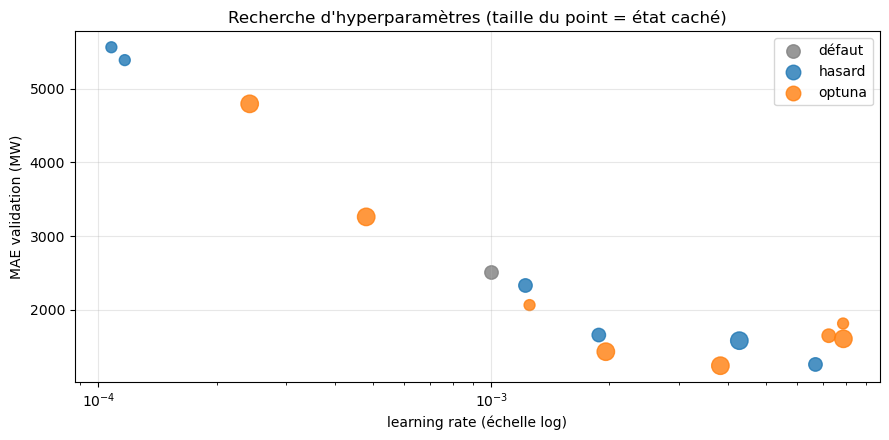

In [14]:
import optuna
def objective(trial):
    hp = None    # TODO : trial.suggest_float("lr", 1e-4, 1e-2, log=True), suggest_categorical("hidden", [32, 64, 128]), suggest_float("dropout", 0.0, 0.4)
    hp = {"lr": trial.suggest_float("lr", 1e-4, 1e-2, log=True),
          "hidden": trial.suggest_categorical("hidden", [32, 64, 128]),
          "dropout": trial.suggest_float("dropout", 0.0, 0.4)}
    # TODO : la MAE de validation de ce réglage
    return entrainer_et_valider(hp, tr_fit, jours_val)
study = None     # TODO : optuna.create_study(direction="minimize") puis optimize(objective, n_trials=8) ; ajouter les essais à `essais`
optuna.logging.set_verbosity(optuna.logging.WARNING)
# TPE avec 3 essais de démarrage au hasard (par défaut : 10, soit plus que nos 8 essais : tout serait tiré au hasard)
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=0, n_startup_trials=3))
t0 = time.time(); study.optimize(objective, n_trials=8); print(f"8 essais Optuna : {time.time() - t0:.0f} s")
essais = [e for e in essais if e["méthode"] != "optuna"]          # si l'on relance la cellule : pas de doublons
for t in study.trials:
    essais.append({"méthode": "optuna", **t.params, "MAE validation (MW)": t.value})
tableau = None   # TODO : tous les essais triés par MAE de validation ; `meilleur` = le réglage de la première ligne
tableau = pd.DataFrame(essais).sort_values("MAE validation (MW)").reset_index(drop=True)
meilleur = {"lr": float(tableau.loc[0, "lr"]), "hidden": int(tableau.loc[0, "hidden"]), "dropout": float(tableau.loc[0, "dropout"])}
display(tableau.style.format({"lr": "{:.2e}", "dropout": "{:.2f}", "MAE validation (MW)": "{:,.0f}"}))
print("Meilleur réglage :", meilleur, "| trouvé par :", tableau.loc[0, "méthode"])
assert tableau is not None and len(tableau) >= 7
# TODO : nuage de points MAE de validation en fonction du learning rate (axe log), une couleur par méthode
fig, ax = plt.subplots(figsize=(9, 4.5))
for (methode, g), c in zip(tableau.groupby("méthode"), ["tab:gray", "tab:blue", "tab:orange"]):
    ax.scatter(g["lr"], g["MAE validation (MW)"], s=30 + g["hidden"], color=c, alpha=0.8, label=methode)
ax.set_xscale("log"); ax.set_xlabel("learning rate (échelle log)"); ax.set_ylabel("MAE validation (MW)")
ax.set_title("Recherche d'hyperparamètres (taille du point = état caché)"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### G3 — Le verdict sur le test, une seule fois
On ré-entraîne le réglage par défaut et le meilleur réglage sur tout le train d'août (validation comprise), avec le même budget, et on mesure sur les sept premiers jours d'août. Le gain mesuré sur la validation se retrouve-t-il sur le test ? Ne soyez pas surpris s'il fond, ou s'il s'inverse : c'est le résultat le plus instructif de cette partie.

In [15]:
# TODO : entraîner_et_valider(DEFAUT, tr_aout, jours_test) et entraîner_et_valider(meilleur, tr_aout, jours_test) : même budget
# TODO : tableau validation / test pour les deux réglages ; le gain de la validation se retrouve-t-il sur le test ?
mae_defaut, mae_meilleur = None, None
mae_defaut = entrainer_et_valider(DEFAUT, tr_aout, jours_test)        # même budget : epochs=3, max_windows=24*180, seed=0
mae_meilleur = entrainer_et_valider(meilleur, tr_aout, jours_test)
val_defaut = tableau.loc[tableau["méthode"] == "défaut", "MAE validation (MW)"].iloc[0]
val_meilleur = tableau.loc[0, "MAE validation (MW)"]
verdict = pd.DataFrame({"MAE validation (MW)": [val_defaut, val_meilleur],
                        "MAE test (MW)": [mae_defaut, mae_meilleur]},
                       index=[f"{nom} (lr={hp['lr']:.1e}, hidden={hp['hidden']}, dropout={hp['dropout']:.2f})"
                              for nom, hp in [("défaut", DEFAUT), ("meilleur", meilleur)]])
verdict.loc["gain du meilleur (%)"] = 100 * (1 - verdict.iloc[1] / verdict.iloc[0])
display(verdict.round(1))
print(f"Gain en validation : {verdict.iloc[2, 0]:+.1f} % | gain sur le test : {verdict.iloc[2, 1]:+.1f} %")
assert mae_defaut is not None and mae_meilleur is not None

,MAE validation (MW),MAE test (MW)
"défaut (lr=1.0e-03, hidden=64, dropout=0.10)",2507.9,1945.2
"meilleur (lr=3.8e-03, hidden=128, dropout=0.03)",1237.9,1398.2
gain du meilleur (%),50.6,28.1


Gain en validation : +50.6 % | gain sur le test : +28.1 %


**À rédiger (3 lignes)** : quel hyperparamètre compte le plus sur le nuage de points ? Le réglage par défaut du TP était-il raisonnable ? Pourquoi ne faut-il regarder le test qu'une seule fois ?

**Pour le projet** : cette partie est le squelette de votre recherche d'hyperparamètres. À partir de J4, chaque appel à `entrainer_et_valider` deviendra un run MLflow (hyperparamètres en paramètres, MAE de validation en métrique).